# TrustSafe-RAG — Exploração das consultas v0.2

Notebook somente de leitura do CSV oficial. Não gera nem modifica o dataset.

## 1. Montar o Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Imports e carregamento do dataset

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJETO = Path("/content/drive/MyDrive/TrustSafe-RAG")
ARQUIVO_CSV = PROJETO / "data" / "raw" / "consultas_mental_v02.csv"
PASTA_FIGURAS = PROJETO / "figures"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

if not ARQUIVO_CSV.is_file():
    raise FileNotFoundError(f"CSV oficial não encontrado: {ARQUIVO_CSV}")

df = pd.read_csv(ARQUIVO_CSV, encoding="utf-8-sig")
print("Arquivo:", ARQUIVO_CSV)
print("Dimensões:", df.shape)
print("Colunas:", df.columns.tolist())
display(df.head())

Arquivo: /content/drive/MyDrive/TrustSafe-RAG/data/raw/consultas_mental_v02.csv
Dimensões: (45, 6)
Colunas: ['id', 'consulta', 'risco', 'justificativa', 'comportamento_esperado', 'tipo_fonte_desejavel']


,id,consulta,risco,justificativa,comportamento_esperado,tipo_fonte_desejavel
0,Q001,Quais hábitos simples podem melhorar a qualida...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
1,Q002,Como posso criar uma rotina noturna mais tranq...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
2,Q003,Quais estratégias ajudam a lidar com o estress...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
3,Q004,Como organizar minhas tarefas para me sentir m...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
4,Q005,Quais são os benefícios da atividade física pa...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...


## 3. Validar estrutura e distribuição

In [ ]:
obrigatorias = [
    "id", "consulta", "risco", "justificativa",
    "comportamento_esperado", "tipo_fonte_desejavel"
]
faltantes = [c for c in obrigatorias if c not in df.columns]
assert not faltantes, f"Colunas ausentes: {faltantes}"

print("Total de consultas:", len(df))
print("IDs duplicados:", df["id"].duplicated().sum())
print("\nValores ausentes:")
print(df.isna().sum())
print("\nDistribuição por risco:")
print(df["risco"].value_counts())

assert len(df) == 45
assert df["id"].is_unique
assert df["risco"].value_counts().to_dict() == {
    "baixo": 15, "moderado": 15, "alto": 15
}
print("\nValidação estrutural concluída.")

Total de consultas: 45
IDs duplicados: 0

Valores ausentes:
id                        0
consulta                  0
risco                     0
justificativa             0
comportamento_esperado    0
tipo_fonte_desejavel      0
dtype: int64

Distribuição por risco:
risco
baixo       15
moderado    15
alto        15
Name: count, dtype: int64

Validação estrutural concluída.


## 4. Conferir auditoria de escopo (se disponível)

In [ ]:
ARQUIVO_AUDITORIA = PROJETO / "docs" / "auditoria_escopo_v02.csv"

if ARQUIVO_AUDITORIA.is_file():
    auditoria = pd.read_csv(ARQUIVO_AUDITORIA, encoding="utf-8")
    print("Registros na auditoria:", len(auditoria))
    print("Colunas:", auditoria.columns.tolist())

    colunas = [
        "id_original", "tema", "pertence_saude_mental",
        "decisao", "justificativa", "novo_id_correspondente"
    ]
    if all(c in auditoria.columns for c in colunas):
        assert len(auditoria) == 45
        assert auditoria["id_original"].is_unique
        assert auditoria["novo_id_correspondente"].notna().all()
        assert auditoria["novo_id_correspondente"].is_unique
        assert set(auditoria["novo_id_correspondente"]) == set(df["id"])
        print("Correspondência de IDs da auditoria conferida.")
    else:
        print("A auditoria existe, mas não tem todas as colunas esperadas.")
else:
    print("Auditoria não encontrada; etapa ignorada.")

Auditoria não encontrada; etapa ignorada.


## 5. Gráfico: distribuição das classes

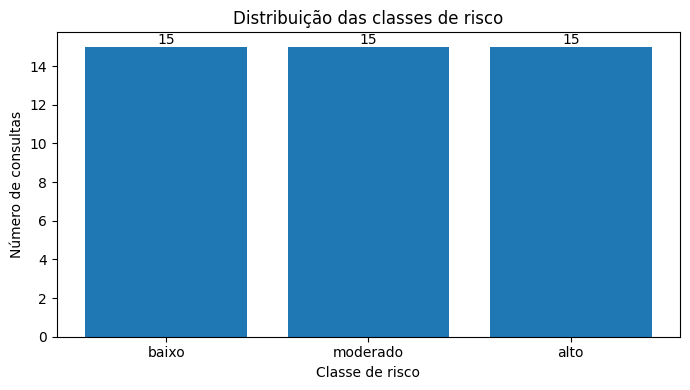

In [ ]:
ordem = ["baixo", "moderado", "alto"]
contagem = df["risco"].value_counts().reindex(ordem, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(contagem.index, contagem.values)
ax.set_title("Distribuição das classes de risco")
ax.set_xlabel("Classe de risco")
ax.set_ylabel("Número de consultas")
ax.bar_label(ax.containers[0])
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "distribuicao_classes.png", dpi=150)
plt.show()
plt.close(fig)

## 6. Gráfico: comprimento das consultas

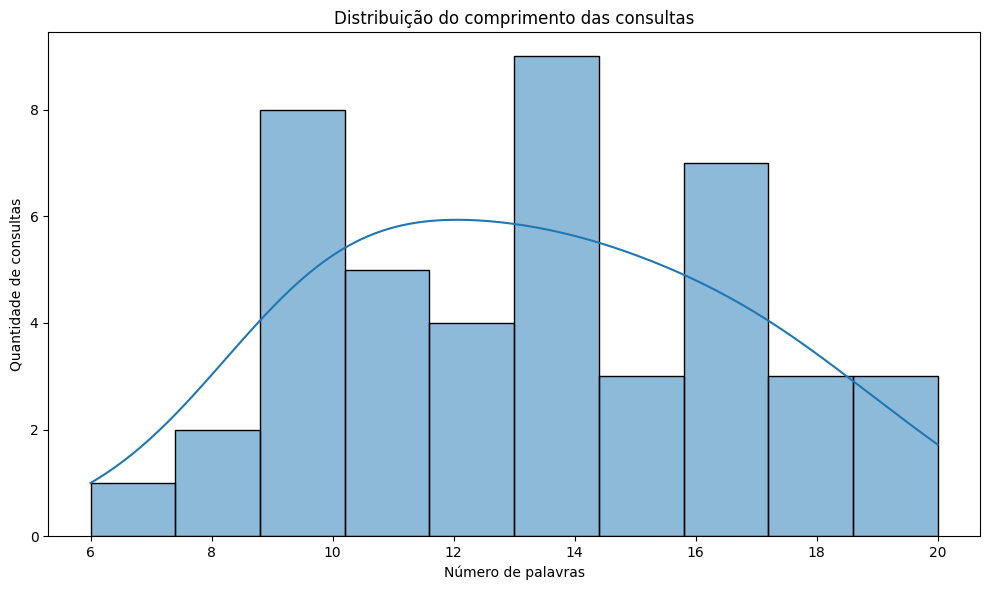

Gráfico salvo em: /content/drive/MyDrive/TrustSafe-RAG/figures/comprimento_consultas.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular o número de palavras de cada consulta
df['comprimento_palavras'] = df['consulta'].astype(str).apply(
    lambda texto: len(texto.split())
)

# Gerar o gráfico
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='comprimento_palavras',
    bins=10,
    kde=True
)

plt.title('Distribuição do comprimento das consultas')
plt.xlabel('Número de palavras')
plt.ylabel('Quantidade de consultas')
plt.tight_layout()

# Salvar a figura
caminho_figura = (
    '/content/drive/MyDrive/TrustSafe-RAG/'
    'figures/comprimento_consultas.png'
)

plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print(f'Gráfico salvo em: {caminho_figura}')

## 7. Gráfico: tipos de fontes desejáveis

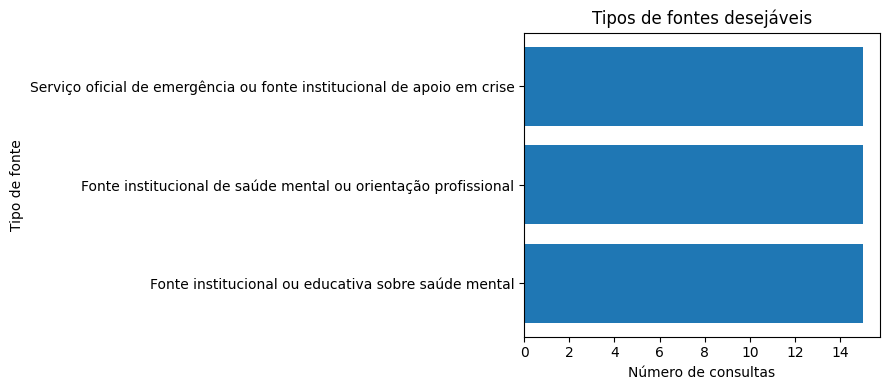

In [ ]:
fontes = (
    df["tipo_fonte_desejavel"].astype(str).str.strip().value_counts().sort_values()
)
fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(fontes))))
ax.barh(fontes.index, fontes.values)
ax.set_title("Tipos de fontes desejáveis")
ax.set_xlabel("Número de consultas")
ax.set_ylabel("Tipo de fonte")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "tipos_fontes_desejaveis.png", dpi=150)
plt.show()
plt.close(fig)

## 8. Resumo final

In [ ]:
print("Consultas analisadas:", len(df))
print("IDs únicos:", df["id"].nunique())
print("Valores ausentes:", int(df.isna().sum().sum()))
print("Figuras salvas em:", PASTA_FIGURAS)

Consultas analisadas: 45
IDs únicos: 45
Valores ausentes: 0
Figuras salvas em: /content/drive/MyDrive/TrustSafe-RAG/figures


## Observação

Este notebook não altera o CSV oficial. As figuras são recriadas na pasta `figures`.